Прочитайте csv файл (використовуйте функцію read_csv)

In [127]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
bs=pd.read_csv("D:/files/bestsellers.csv")
print(bs)

                                                  Name  \
0                        10-Day Green Smoothie Cleanse   
1                                    11/22/63: A Novel   
2              12 Rules for Life: An Antidote to Chaos   
3                               1984 (Signet Classics)   
4    5,000 Awesome Facts (About Everything!) (Natio...   
..                                                 ...   
545       Wrecking Ball (Diary of a Wimpy Kid Book 14)   
546  You Are a Badass: How to Stop Doubting Your Gr...   
547  You Are a Badass: How to Stop Doubting Your Gr...   
548  You Are a Badass: How to Stop Doubting Your Gr...   
549  You Are a Badass: How to Stop Doubting Your Gr...   

                       Author  User Rating  Reviews  Price  Year        Genre  
0                    JJ Smith          4.7    17350      8  2016  Non Fiction  
1                Stephen King          4.6     2052     22  2011      Fiction  
2          Jordan B. Peterson          4.7    18979     15  201

Виведіть перші п'ять рядків (використовується функція head)

In [128]:
print(bs.head)

<bound method NDFrame.head of                                                   Name  \
0                        10-Day Green Smoothie Cleanse   
1                                    11/22/63: A Novel   
2              12 Rules for Life: An Antidote to Chaos   
3                               1984 (Signet Classics)   
4    5,000 Awesome Facts (About Everything!) (Natio...   
..                                                 ...   
545       Wrecking Ball (Diary of a Wimpy Kid Book 14)   
546  You Are a Badass: How to Stop Doubting Your Gr...   
547  You Are a Badass: How to Stop Doubting Your Gr...   
548  You Are a Badass: How to Stop Doubting Your Gr...   
549  You Are a Badass: How to Stop Doubting Your Gr...   

                       Author  User Rating  Reviews  Price  Year        Genre  
0                    JJ Smith          4.7    17350      8  2016  Non Fiction  
1                Stephen King          4.6     2052     22  2011      Fiction  
2          Jordan B. Peterson    

Виведіть розміри датасету (використовуйте атрибут shape)

In [129]:
print(bs.shape)

(550, 7)


Про скільки книг зберігає дані датасет?
Відповідь: 550

In [130]:
bs.columns = ['name', 'author', 'user_rating', 'reviews', 'price', 'year', 'genre']


Перевірте, чи у всіх рядків вистачає даних: виведіть кількість пропусків (na) у кожному зі стовпців (використовуйте функції isna та sum)

In [131]:
print(bs.isnull().sum())

name           0
author         0
user_rating    0
reviews        0
price          0
year           0
genre          0
dtype: int64


Відповідь: Чи є в якихось змінних пропуски? Ні

Перевірте, які є унікальні значення в колонці genre (використовуйте функцію unique)

In [132]:
print(bs["genre"].unique())

<ArrowStringArray>
['Non Fiction', 'Fiction']
Length: 2, dtype: str


Відповідь: Які є унікальні жанри? 'Non Fiction', 'Fiction'

Тепер подивіться на розподіл цін: побудуйте діаграму (використовуйте kind='hist')

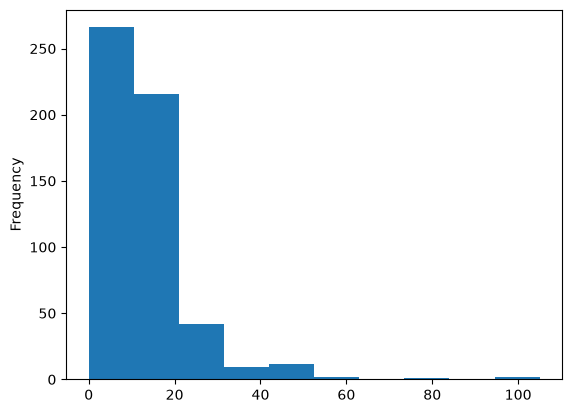

In [133]:
bs["price"].plot(kind='hist')
plt.show()

Визначте, яка ціна у нас максимальна, мінімальна, середня, медіанна (використовуйте функції max, min, mean, median)

In [134]:
print(bs["price"].agg(['min', 'max', 'mean', 'median']))

min         0.0
max       105.0
mean       13.1
median     11.0
Name: price, dtype: float64


Відповідь: Максимальна ціна? 105
Відповідь: Мінімальна ціна? 0
Відповідь: Середня ціна? 13.1
Відповідь: Медіанна ціна? 11


In [135]:
print(bs["user_rating"].max())

4.9


Відповідь: Який рейтинг у датасеті найвищий? Відповідь: 4.9

In [136]:
count_rating=bs[bs["user_rating"] == 4.9]
print(len(count_rating))


52


Відповідь: Скільки книг мають такий рейтинг? Відповідь: 52

In [137]:
print(bs["name"][bs["reviews"]== bs["reviews"].max()])

534    Where the Crawdads Sing
Name: name, dtype: str


Відповідь: Яка книга має найбільше відгуків? Відповідь: Where the Crawdads Sing

In [138]:
print(bs["name"][bs["reviews"]== bs["reviews"].max()])

534    Where the Crawdads Sing
Name: name, dtype: str


In [139]:
bs2015=bs[bs["year"]== 2015]
print(bs2015["name"][bs2015["price"]== bs2015["price"].max()])

277    Publication Manual of the American Psychologic...
Name: name, dtype: str


Відповідь: З тих книг, що потрапили до Топ-50 у 2015 році, яка книга найдорожча (можна використати проміжний датафрейм)? Відповідь:
Publication Manual of the American Psychologic...

In [140]:

bs2010=bs[(bs["genre"]== "Fiction") & (bs["year"]== 2010)]
print(len(bs2010))

20


Скільки книг жанру Fiction потрапили до Топ-50 у 2010 році (використовуйте &)? Відповідь: 20

In [141]:
bs10_11=bs[(bs["user_rating"]==4.9) & ((bs["year"]==2010) | (bs["year"]==2011))]
print(len(bs10_11))

1


Відповідь: Скільки книг з рейтингом 4.9 потрапило до рейтингу у 2010 та 2011 роках (використовуйте | або функцію isin)? Відповідь: 1


І насамкінець, давайте відсортуємо за зростанням ціни всі книги, які потрапили до рейтингу в 2015 році і коштують дешевше за 8 доларів (використовуйте функцію sort_values).

In [142]:
bs15=bs[(bs["year"]==2015) & (bs["price"] < 8)]
bs15=bs15.sort_values("price")
print(bs15)

                                                  name              author  \
507                              To Kill a Mockingbird          Harper Lee   
54   Creative Haven Creative Cats Coloring Book (Ad...     Marjorie Sarnat   
206                         Knock-Knock Jokes for Kids         Rob Elliott   
111                                    First 100 Words        Roger Priddy   
210                      Laugh-Out-Loud Jokes for Kids         Rob Elliott   
123                               Giraffes Can't Dance       Giles Andreae   
55   Creative Haven Owls Coloring Book (Adult Color...     Marjorie Sarnat   
63                      Dear Zoo: A Lift-the-Flap Book        Rod Campbell   
224                                   Love You Forever       Robert Munsch   
478                        The Very Hungry Caterpillar          Eric Carle   
89   Dover Creative Haven Art Nouveau Animal Design...         Marty Noble   
201  Killing Reagan: The Violent Assault That Chang...       Bil

In [143]:
print(bs15.iloc[-1])


name           Old School (Diary of a Wimpy Kid #10)
author                                   Jeff Kinney
user_rating                                      4.8
reviews                                         6169
price                                              7
year                                            2015
genre                                        Fiction
Name: 253, dtype: object


Відповідь: Яка книга остання у відсортованому списку? Відповідь: Old School (Diary of a Wimpy Kid #10)

## Агрегування даних та з'єднання таблиць



Для початку давайте подивимося на максимальну та мінімальну ціни для кожного з жанрів (використовуйте функції groupby та agg, для підрахунку мінімальних та максимальних значень використовуйте max та min). Не беріть усі стовпці, виберіть тільки потрібні вам

In [144]:
bs1=bs.groupby("genre")["price"].agg(["min", "max"])
print(bs1)

             min  max
genre                
Fiction        0   82
Non Fiction    0  105


Відповідь: Максимальна ціна для жанру Fiction: Відповідь 82

Відповідь: Мінімальна ціна для жанру Fiction: Відповідь 0

Відповідь: Максимальна ціна для жанру Non Fiction: Відповідь 105

Відповідь: Мінімальна ціна для жанру Non Fiction: Відповідь 0

Тепер створіть новий датафрейм, який вміщатиме кількість книг для кожного з авторів (використовуйте функції groupby та agg, для підрахунку кількості використовуйте count). Не беріть усі стовпці, виберете тільки потрібні

In [145]:
author_count=bs.groupby("author")["name"].agg(['count'])
print(author_count)

                            count
author                           
Abraham Verghese                2
Adam Gasiewski                  1
Adam Mansbach                   1
Adir Levy                       1
Admiral William H. McRaven      1
...                           ...
Walter Isaacson                 3
William Davis                   2
William P. Young                2
Wizards RPG Team                3
Zhi Gang Sha                    2

[248 rows x 1 columns]


Відповідь: Якої розмірності вийшла таблиця? Відповідь: 248 rows x 1 columns

In [146]:
max_books=author_count[author_count["count"]==author_count["count"].max()]
print(max_books)

             count
author            
Jeff Kinney     12


Відповідь: Який автор має найбільше книг? Відповідь: Jeff Kinney

Відповідь: Скільки книг цього автора? Відповідь: 12

Тепер створіть другий датафрейм, який буде вміщати середній рейтинг для кожного автора (використовуйте функції groupby та agg, для підрахунку середнього значення використовуйте mean). Не беріть усі стовпці, виберете тільки потрібні

In [147]:
mean_rating=bs.groupby("author")["user_rating"].agg(["mean"])
print(mean_rating.round(1))

                            mean
author                          
Abraham Verghese             4.6
Adam Gasiewski               4.4
Adam Mansbach                4.8
Adir Levy                    4.8
Admiral William H. McRaven   4.7
...                          ...
Walter Isaacson              4.6
William Davis                4.4
William P. Young             4.6
Wizards RPG Team             4.8
Zhi Gang Sha                 4.6

[248 rows x 1 columns]


In [148]:
print(mean_rating[mean_rating["mean"]==mean_rating["mean"].min()])

             mean
author           
Donna Tartt   3.9


Відповідь: У якого автора середній рейтинг мінімальний? Відповідь: Donna Tartt

Відповідь: Який у цього автора середній рейтинг? Відповідь: 3.9

З'єднайте останні два датафрейми так, щоб для кожного автора було видно кількість книг та середній рейтинг (Використовуйте функцію concat з параметром axis=1). Збережіть результат у змінну


In [149]:
df=pd.concat([mean_rating,author_count], axis=1)
print(df.round(1))

                            mean  count
author                                 
Abraham Verghese             4.6      2
Adam Gasiewski               4.4      1
Adam Mansbach                4.8      1
Adir Levy                    4.8      1
Admiral William H. McRaven   4.7      1
...                          ...    ...
Walter Isaacson              4.6      3
William Davis                4.4      2
William P. Young             4.6      2
Wizards RPG Team             4.8      3
Zhi Gang Sha                 4.6      2

[248 rows x 2 columns]


Відсортуйте датафрейм за зростаючою кількістю книг та зростаючим рейтингом (використовуйте функцію sort_values)

In [150]:
df=df.sort_values(["count", "mean"])
print(df)

                                        mean  count
author                                             
Muriel Barbery                      4.000000      1
Chris Cleave                        4.100000      1
Ian K. Smith M.D.                   4.100000      1
Pierre Dukan                        4.100000      1
Elizabeth Strout                    4.200000      1
...                                      ...    ...
American Psychological Association  4.500000     10
Suzanne Collins                     4.663636     11
Gary Chapman                        4.736364     11
Rick Riordan                        4.772727     11
Jeff Kinney                         4.800000     12

[248 rows x 2 columns]


Відповідь: Який автор перший у списку? Muriel Barbery

## Візуалізація


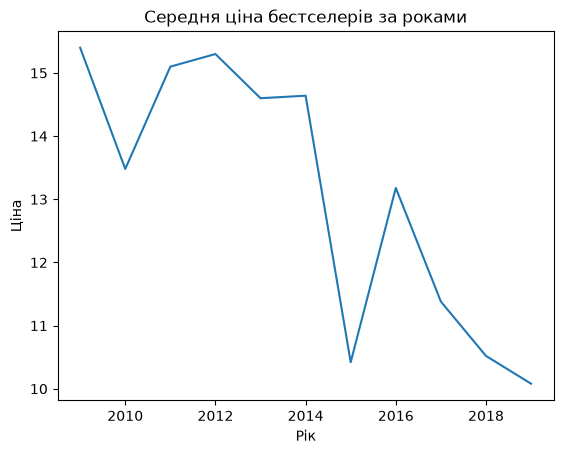

In [151]:
yearly=bs.groupby("year")["price"].mean()
plt.plot(yearly.index, yearly.values)
plt.xlabel("Рік")
plt.ylabel("Ціна")
plt.title("Середня ціна бестселерів за роками")
plt.show()

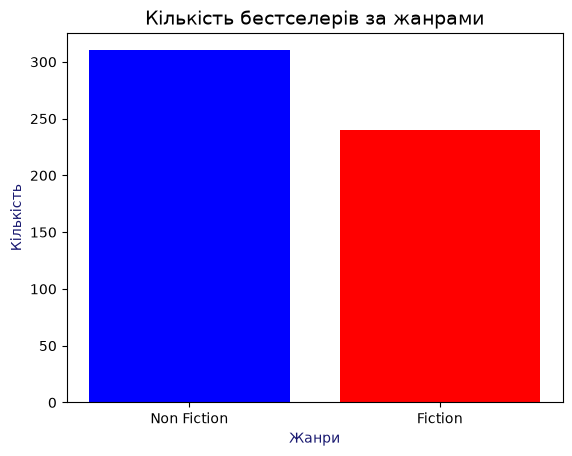

In [152]:
count_genre=bs["genre"].value_counts()
plt.bar(count_genre.index, count_genre.values,
       color=["b", "r"])
plt.xlabel("Жанри", color="midnightblue")
plt.ylabel("Кількість", color="midnightblue")
plt.title("Кількість бестселерів за жанрами", fontsize=14)
plt.show()

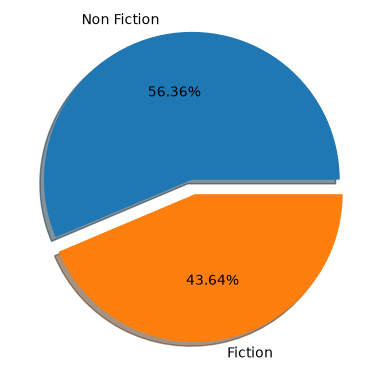

In [153]:
plt.pie(count_genre.values, labels=count_genre.index, shadow=True, explode=[0.1, 0], autopct="%.2f%%")
plt.show()